<a href="https://colab.research.google.com/github/SehrishbAsghar/ASSIGNMENT/blob/main/MMC_ASSIGNMENT02_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Importing the data

In [4]:
from google.colab import files
files.upload()

import pandas as pd
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import networkx as nx
df = pd.read_csv("Advertising.csv")

Saving Advertising.csv to Advertising (1).csv


In [5]:
import os
print(os.listdir())

['.config', 'Advertising.csv', 'Advertising (1).csv', 'archive.zip', 'sample_data']


In [6]:
df = pd.read_csv('Advertising.csv')
A_data = df.head(6).to_numpy()
print(A_data.shape)

(6, 4)


 Standardizing the data and finding distances

In [7]:
Z = (A_data - A_data.mean(axis=0)) / A_data.std(axis=0)
dist = np.linalg.norm(Z[:, None, :] - Z[None, :, :], axis=2)

pairs = dist[np.triu_indices(6, 1)]
threshold = np.median(pairs)
print('Threshold:', round(threshold, 3))

Threshold: 3.131


Adjacency, degree and Laplacian matrices

In [8]:
A = (dist <= threshold).astype(int)
np.fill_diagonal(A, 0)
print('Adjacency matrix A:\n', A)

D = np.diag(A.sum(axis=1))
print('Degree matrix D:\n', D)

L = D - A
print('Laplacian L = D - A:\n', L)

Adjacency matrix A:
 [[0 0 0 1 1 0]
 [0 0 1 1 1 0]
 [0 1 0 1 0 1]
 [1 1 1 0 1 0]
 [1 1 0 1 0 0]
 [0 0 1 0 0 0]]
Degree matrix D:
 [[2 0 0 0 0 0]
 [0 3 0 0 0 0]
 [0 0 3 0 0 0]
 [0 0 0 4 0 0]
 [0 0 0 0 3 0]
 [0 0 0 0 0 1]]
Laplacian L = D - A:
 [[ 2  0  0 -1 -1  0]
 [ 0  3 -1 -1 -1  0]
 [ 0 -1  3 -1  0 -1]
 [-1 -1 -1  4 -1  0]
 [-1 -1  0 -1  3  0]
 [ 0  0 -1  0  0  1]]


Checking the matrices

In [9]:
print('A symmetric:', np.array_equal(A, A.T))
print('Sum of degrees:', np.trace(D), '= 2 x edges:', 2 * (A.sum() // 2))
print('Row sums of L:', L.sum(axis=1))
print('Eigenvalues of L:', np.round(np.linalg.eigvalsh(L), 3))

A symmetric: True
Sum of degrees: 16 = 2 x edges: 16
Row sums of L: [0 0 0 0 0 0]
Eigenvalues of L: [-0.     0.731  2.135  3.466  4.549  5.118]


Drawing the graph

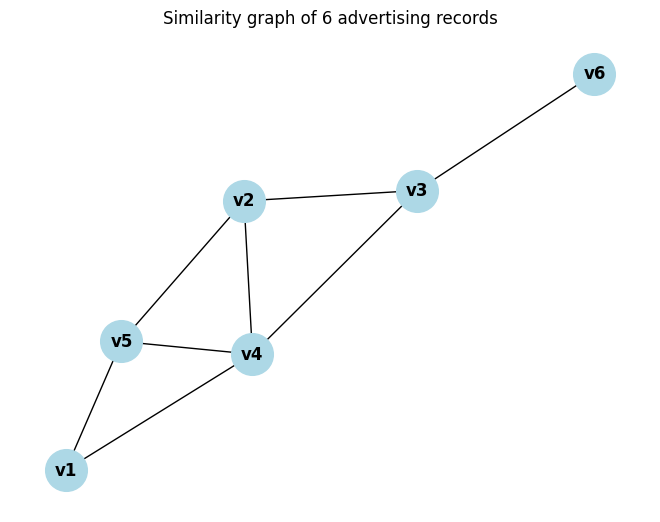

Edges: [('v1', 'v4'), ('v1', 'v5'), ('v2', 'v3'), ('v2', 'v4'), ('v2', 'v5'), ('v3', 'v4'), ('v3', 'v6'), ('v4', 'v5')]


In [10]:
G = nx.from_numpy_array(A)
G = nx.relabel_nodes(G, {i: f'v{i+1}' for i in range(6)})
nx.draw(G, with_labels=True, node_color='lightblue', node_size=900, font_weight='bold')
plt.title('Similarity graph of 6 advertising records')
plt.show()
print('Edges:', list(G.edges()))